In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1) Seed
SEED = 29059 + 2026   # = 31085

# 2) Veriyi oku
df = pd.read_csv("bank-additional.csv", sep=";")
print("Boyut:", df.shape)
print(df["y"].value_counts())

# 3) duration sütununu çıkar
df = df.drop(columns=["duration"])

# 4) Hedefi 0/1 yap
y = (df["y"] == "yes").astype(int)

# 5) %80 development / %20 test, stratified
dev, test = train_test_split(df, test_size=0.2, stratify=y, random_state=SEED)

print("Development:", len(dev), "| Test:", len(test))
print("Development pozitif oran:", round((dev["y"] == "yes").mean(), 4))
print("Test pozitif oran:       ", round((test["y"] == "yes").mean(), 4))

Boyut: (4119, 21)
y
no     3668
yes     451
Name: count, dtype: int64
Development: 3295 | Test: 824
Development pozitif oran: 0.1096
Test pozitif oran:        0.1092


In [4]:
split = pd.DataFrame({
    "orig_index": list(dev.index) + list(test.index),
    "set": ["development"] * len(dev) + ["test"] * len(test),
}).sort_values("orig_index")
split.to_csv("dataset_split.csv", index=False)
print(split.head())

      orig_index          set
2223           0  development
3354           1         test
644            2  development
3476           3         test
164            4  development


In [5]:
import numpy as np
import matplotlib.pyplot as plt

num_cols = ["age", "campaign", "pdays", "previous", "emp.var.rate",
            "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
cat_cols = ["job", "marital", "education", "default", "housing", "loan",
            "contact", "month", "day_of_week", "poutcome"]

# Kopya kayıtlar (ham dosyanın tamamında, bölünmeden önceki durum)
raw = pd.read_csv("bank-additional.csv", sep=";")
print("Tamamen aynı satır sayısı:", raw.duplicated().sum())
print("duration hariç aynı satır:", raw.drop(columns="duration").duplicated(keep=False).sum())

# Development özeti
ozet = pd.DataFrame({
    "tip": dev.dtypes.astype(str),
    "benzersiz": dev.nunique(),
    "unknown_sayisi": (dev == "unknown").sum(),
})
ozet

Tamamen aynı satır sayısı: 0
duration hariç aynı satır: 38


,tip,benzersiz,unknown_sayisi
age,int64,67,0
job,object,12,32
marital,object,4,10
education,object,8,140
default,object,3,632
housing,object,3,85
loan,object,3,85
contact,object,2,0
month,object,10,0
day_of_week,object,5,0


y
no     2934
yes     361
Name: count, dtype: int64
Pozitif oran: 0.1096


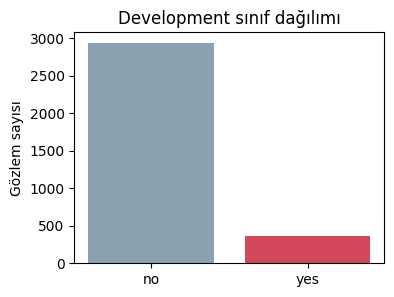

In [6]:
sayim = dev["y"].value_counts()
print(sayim)
print("Pozitif oran:", round(sayim["yes"] / len(dev), 4))

plt.figure(figsize=(4, 3))
plt.bar(sayim.index, sayim.values, color=["#8aa1b1", "#d1495b"])
plt.title("Development sınıf dağılımı")
plt.ylabel("Gözlem sayısı")
plt.show()

                ortalama   medyan      SD     IQR      min     maks
age                40.07    38.00   10.31   15.00    18.00    88.00
campaign            2.53     2.00    2.57    2.00     1.00    29.00
pdays             959.81   999.00  193.40    0.00     0.00   999.00
previous            0.19     0.00    0.54    0.00     0.00     6.00
emp.var.rate        0.07     1.10    1.57    3.20    -3.40     1.40
cons.price.idx     93.57    93.44    0.58    0.92    92.20    94.77
cons.conf.idx     -40.50   -41.80    4.62    6.30   -50.80   -26.90
euribor3m           3.61     4.86    1.74    3.63     0.64     5.04
nr.employed      5166.09  5191.00   73.77  129.00  4963.60  5228.10

pdays = 999 oranı: 0.961


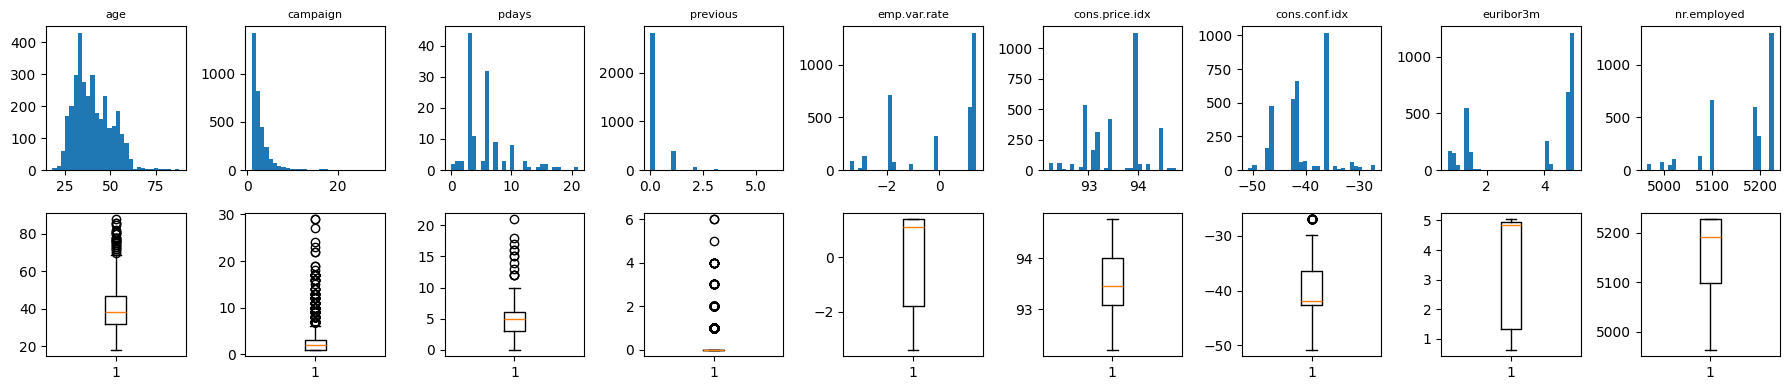

In [7]:
def ozet_istatistik(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({"ortalama": s.mean(), "medyan": s.median(), "SD": s.std(),
                      "IQR": q3 - q1, "min": s.min(), "maks": s.max()})

print(dev[num_cols].apply(ozet_istatistik).T.round(2))
print("\npdays = 999 oranı:", round((dev["pdays"] == 999).mean(), 3))

fig, ax = plt.subplots(2, 9, figsize=(18, 4))
for i, c in enumerate(num_cols):
    s = dev[c] if c != "pdays" else dev.loc[dev["pdays"] != 999, c]
    ax[0, i].hist(s, bins=30)
    ax[0, i].set_title(c, fontsize=8)
    ax[1, i].boxplot(s)
plt.tight_layout()
plt.show()

In [8]:
for c in num_cols:
    s = dev[c] if c != "pdays" else dev.loc[dev["pdays"] != 999, c]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    disari = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100
    print(f"{c:15s} IQR dışı: %{disari:.1f}")

age             IQR dışı: %0.8
campaign        IQR dışı: %5.5
pdays           IQR dışı: %9.2
previous        IQR dışı: %14.8
emp.var.rate    IQR dışı: %0.0
cons.price.idx  IQR dışı: %0.0
cons.conf.idx   IQR dışı: %1.1
euribor3m       IQR dışı: %0.0
nr.employed     IQR dışı: %0.0


job
admin.           814
blue-collar      721
technician       540
services         320
management       260
retired          131
self-employed    125
entrepreneur     105
unemployed        91
housemaid         87
student           69
unknown           32
Name: count, dtype: int64 

education
university.degree      1009
high.school             740
basic.9y                468
professional.course     415
basic.4y                344
basic.6y                178
unknown                 140
illiterate                1
Name: count, dtype: int64 

default
no         2662
unknown     632
yes           1
Name: count, dtype: int64 

poutcome
nonexistent    2806
failure         373
success         116
Name: count, dtype: int64 



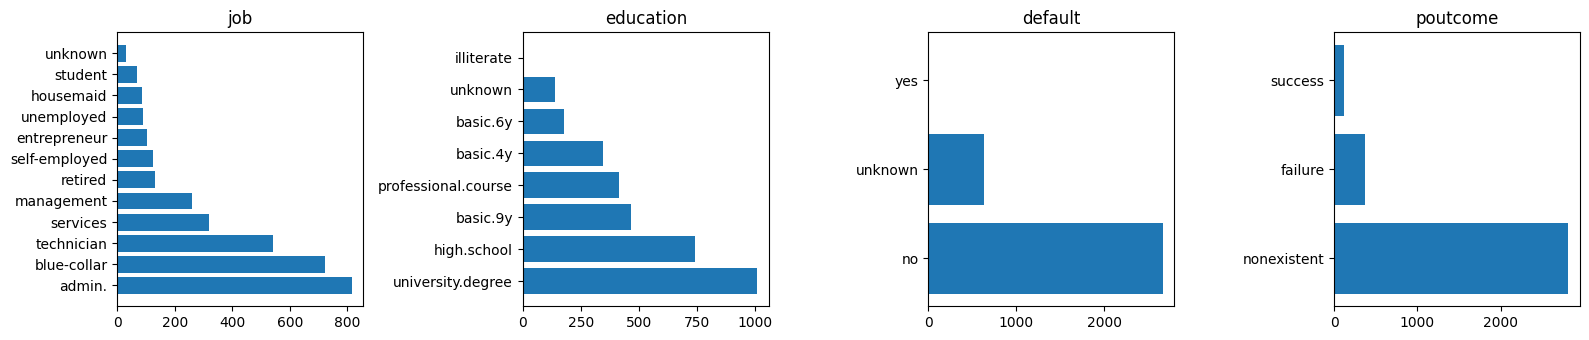

In [9]:
for c in ["job", "education", "default", "poutcome"]:
    print(dev[c].value_counts(), "\n")

fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, c in zip(ax, ["job", "education", "default", "poutcome"]):
    vc = dev[c].value_counts()
    a.barh(vc.index, vc.values)
    a.set_title(c)
plt.tight_layout()
plt.show()

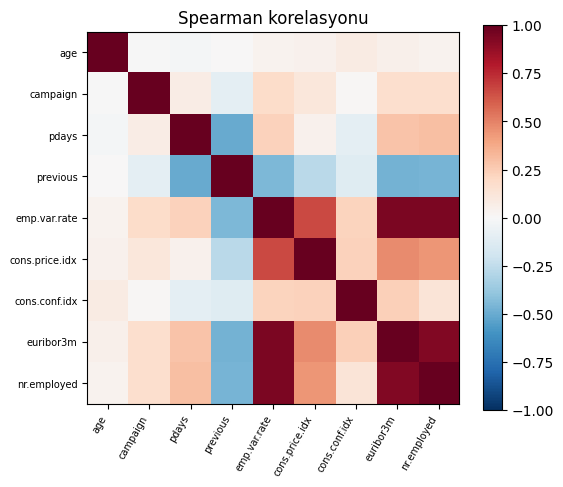

Pozitif oran | daha önce aranmamış : 0.088
Pozitif oran | daha önce aranmış   : 0.631
     euribor3m  campaign
y                       
no       4.857       2.0
yes      1.262       2.0


In [10]:
kor = dev[num_cols].corr(method="spearman")
plt.figure(figsize=(6, 5))
plt.imshow(kor, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(num_cols)), num_cols, rotation=60, ha="right", fontsize=7)
plt.yticks(range(len(num_cols)), num_cols, fontsize=7)
plt.colorbar()
plt.title("Spearman korelasyonu")
plt.show()

hedef = (dev["y"] == "yes")
print("Pozitif oran | daha önce aranmamış :", round(hedef[dev["pdays"] == 999].mean(), 3))
print("Pozitif oran | daha önce aranmış   :", round(hedef[dev["pdays"] != 999].mean(), 3))
print(dev.groupby("y")[["euribor3m", "campaign"]].median())

In [11]:
import numpy as np
import matplotlib.pyplot as plt

num_cols = ["age", "campaign", "pdays", "previous", "emp.var.rate",
            "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
cat_cols = ["job", "marital", "education", "default", "housing", "loan",
            "contact", "month", "day_of_week", "poutcome"]

# Kopya kayıtlar (ham dosyanın tamamında, bölünmeden önceki durum)
raw = pd.read_csv("bank-additional.csv", sep=";")
print("Tamamen aynı satır sayısı:", raw.duplicated().sum())
print("duration hariç aynı satır:", raw.drop(columns="duration").duplicated(keep=False).sum())

# Development özeti
ozet = pd.DataFrame({
    "tip": dev.dtypes.astype(str),
    "benzersiz": dev.nunique(),
    "unknown_sayisi": (dev == "unknown").sum(),
})
ozet

Tamamen aynı satır sayısı: 0
duration hariç aynı satır: 38


,tip,benzersiz,unknown_sayisi
age,int64,67,0
job,object,12,32
marital,object,4,10
education,object,8,140
default,object,3,632
housing,object,3,85
loan,object,3,85
contact,object,2,0
month,object,10,0
day_of_week,object,5,0


y
no     2934
yes     361
Name: count, dtype: int64
Pozitif oran: 0.1096


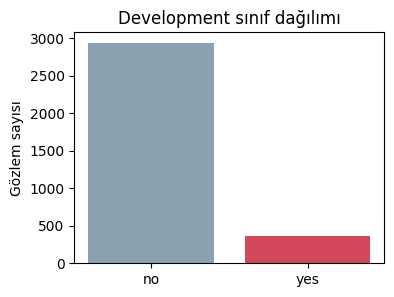

In [12]:
sayim = dev["y"].value_counts()
print(sayim)
print("Pozitif oran:", round(sayim["yes"] / len(dev), 4))

plt.figure(figsize=(4, 3))
plt.bar(sayim.index, sayim.values, color=["#8aa1b1", "#d1495b"])
plt.title("Development sınıf dağılımı")
plt.ylabel("Gözlem sayısı")
plt.show()

y
no     2934
yes     361
Name: count, dtype: int64
Pozitif oran: 0.1096


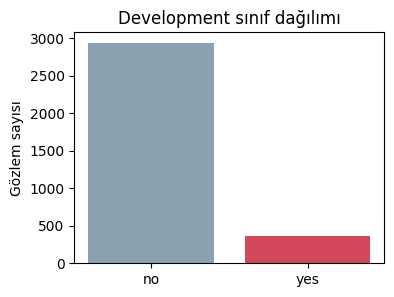

In [13]:
sayim = dev["y"].value_counts()
print(sayim)
print("Pozitif oran:", round(sayim["yes"] / len(dev), 4))

plt.figure(figsize=(4, 3))
plt.bar(sayim.index, sayim.values, color=["#8aa1b1", "#d1495b"])
plt.title("Development sınıf dağılımı")
plt.ylabel("Gözlem sayısı")
plt.show()

                ortalama   medyan      SD     IQR      min     maks
age                40.07    38.00   10.31   15.00    18.00    88.00
campaign            2.53     2.00    2.57    2.00     1.00    29.00
pdays             959.81   999.00  193.40    0.00     0.00   999.00
previous            0.19     0.00    0.54    0.00     0.00     6.00
emp.var.rate        0.07     1.10    1.57    3.20    -3.40     1.40
cons.price.idx     93.57    93.44    0.58    0.92    92.20    94.77
cons.conf.idx     -40.50   -41.80    4.62    6.30   -50.80   -26.90
euribor3m           3.61     4.86    1.74    3.63     0.64     5.04
nr.employed      5166.09  5191.00   73.77  129.00  4963.60  5228.10

pdays = 999 oranı: 0.961


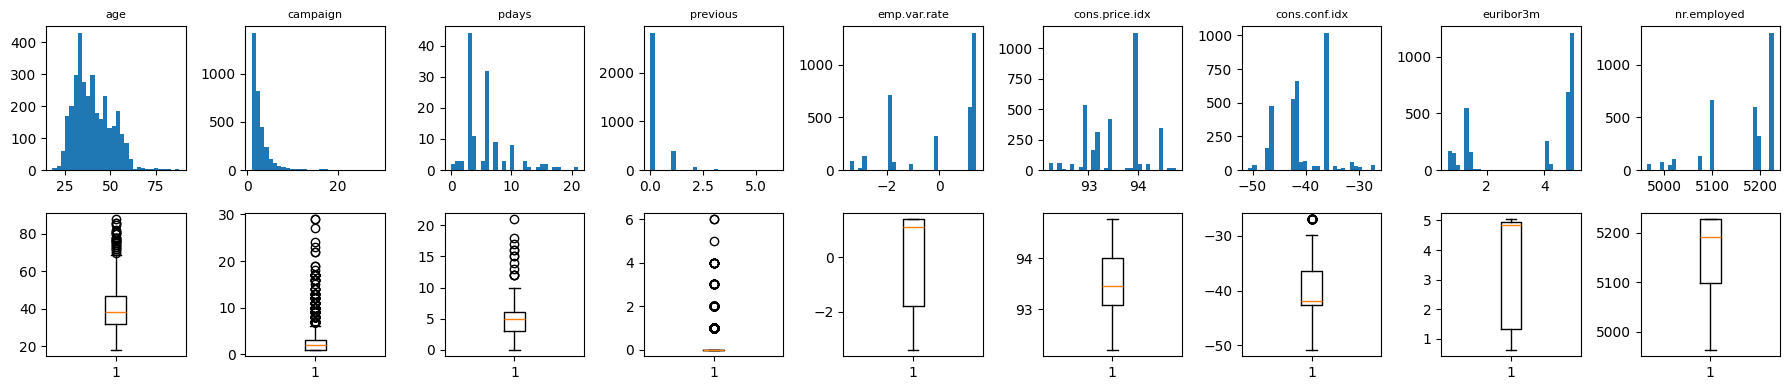

In [14]:
def ozet_istatistik(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({"ortalama": s.mean(), "medyan": s.median(), "SD": s.std(),
                      "IQR": q3 - q1, "min": s.min(), "maks": s.max()})

print(dev[num_cols].apply(ozet_istatistik).T.round(2))
print("\npdays = 999 oranı:", round((dev["pdays"] == 999).mean(), 3))

fig, ax = plt.subplots(2, 9, figsize=(18, 4))
for i, c in enumerate(num_cols):
    s = dev[c] if c != "pdays" else dev.loc[dev["pdays"] != 999, c]
    ax[0, i].hist(s, bins=30)
    ax[0, i].set_title(c, fontsize=8)
    ax[1, i].boxplot(s)
plt.tight_layout()
plt.show()

In [15]:
for c in num_cols:
    s = dev[c] if c != "pdays" else dev.loc[dev["pdays"] != 999, c]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    disari = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100
    print(f"{c:15s} IQR dışı: %{disari:.1f}")

age             IQR dışı: %0.8
campaign        IQR dışı: %5.5
pdays           IQR dışı: %9.2
previous        IQR dışı: %14.8
emp.var.rate    IQR dışı: %0.0
cons.price.idx  IQR dışı: %0.0
cons.conf.idx   IQR dışı: %1.1
euribor3m       IQR dışı: %0.0
nr.employed     IQR dışı: %0.0


job
admin.           814
blue-collar      721
technician       540
services         320
management       260
retired          131
self-employed    125
entrepreneur     105
unemployed        91
housemaid         87
student           69
unknown           32
Name: count, dtype: int64 

education
university.degree      1009
high.school             740
basic.9y                468
professional.course     415
basic.4y                344
basic.6y                178
unknown                 140
illiterate                1
Name: count, dtype: int64 

default
no         2662
unknown     632
yes           1
Name: count, dtype: int64 

poutcome
nonexistent    2806
failure         373
success         116
Name: count, dtype: int64 



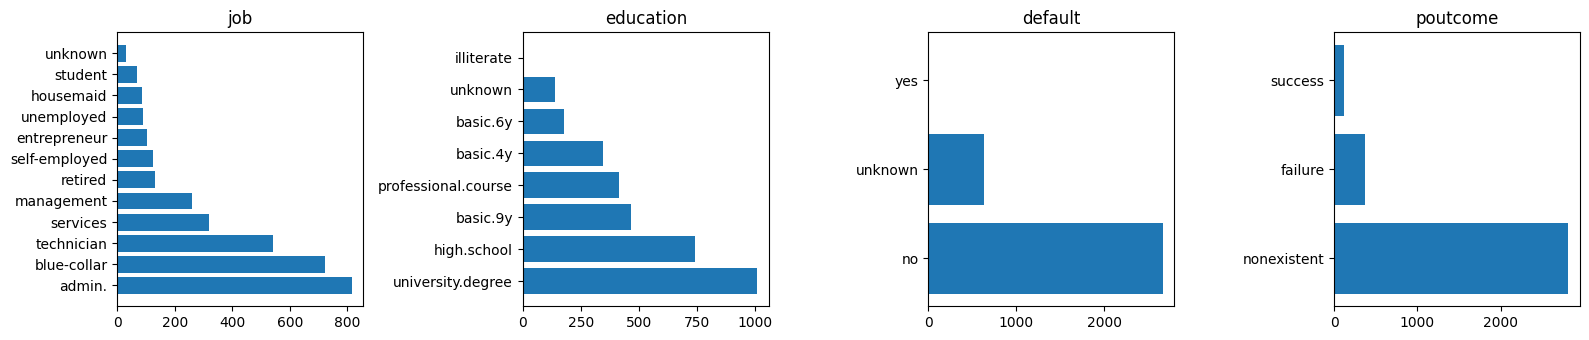

In [16]:
for c in ["job", "education", "default", "poutcome"]:
    print(dev[c].value_counts(), "\n")

fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, c in zip(ax, ["job", "education", "default", "poutcome"]):
    vc = dev[c].value_counts()
    a.barh(vc.index, vc.values)
    a.set_title(c)
plt.tight_layout()
plt.show()

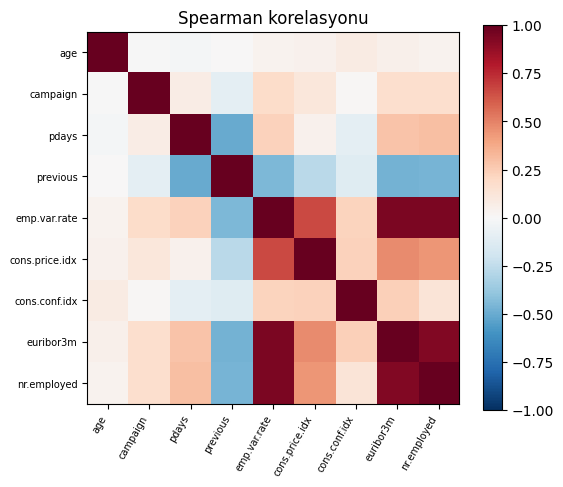

Pozitif oran | daha önce aranmamış : 0.088
Pozitif oran | daha önce aranmış   : 0.631
     euribor3m  campaign
y                       
no       4.857       2.0
yes      1.262       2.0


In [17]:
kor = dev[num_cols].corr(method="spearman")
plt.figure(figsize=(6, 5))
plt.imshow(kor, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(num_cols)), num_cols, rotation=60, ha="right", fontsize=7)
plt.yticks(range(len(num_cols)), num_cols, fontsize=7)
plt.colorbar()
plt.title("Spearman korelasyonu")
plt.show()

hedef = (dev["y"] == "yes")
print("Pozitif oran | daha önce aranmamış :", round(hedef[dev["pdays"] == 999].mean(), 3))
print("Pozitif oran | daha önce aranmış   :", round(hedef[dev["pdays"] != 999].mean(), 3))
print(dev.groupby("y")[["euribor3m", "campaign"]].median())

In [18]:
def ozellikleri_hazirla(df):
    X = df.drop(columns=["y"]).copy()
    X["pdays_never"] = (X["pdays"] == 999).astype(float)          # yeni 0/1 sütun
    X["pdays"] = X["pdays"].where(X["pdays"] != 999, np.nan)       # 999 -> boş
    return X

X_dev = ozellikleri_hazirla(dev).reset_index(drop=True)
y_dev = (dev["y"] == "yes").astype(int).to_numpy()
print(X_dev.shape)
print(X_dev[["pdays", "pdays_never"]].head())

(3295, 20)
   pdays  pdays_never
0    NaN          1.0
1    NaN          1.0
2    NaN          1.0
3    NaN          1.0
4    NaN          1.0


In [20]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder

class YuzdelikKirpici(BaseEstimator, TransformerMixin):
    """Alt/üst eşikleri eğitim verisinden öğrenir (%1 ve %99), sonra uçları o eşiklere çeker."""
    def __init__(self, alt=1, ust=99):
        self.alt, self.ust = alt, ust
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_ = np.nanpercentile(X, self.alt, axis=0)
        self.hi_ = np.nanpercentile(X, self.ust, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

OLCEKLER = {"standard": StandardScaler, "minmax": MinMaxScaler, "robust": RobustScaler}

def on_isleme_yap(olcek="standard", kirp=False):
    sayisal_adimlar = [("doldur", SimpleImputer(strategy="median"))]
    if kirp:
        sayisal_adimlar.append(("kirp", YuzdelikKirpici()))
    sayisal_adimlar.append(("olcekle", OLCEKLER[olcek]()))

    return ColumnTransformer([
        ("sayisal", Pipeline(sayisal_adimlar), num_cols),
        ("bayrak", "passthrough", ["pdays_never"]),
        ("kategorik", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])

In [21]:
from sklearn.model_selection import train_test_split

# Örnek: development'ı ikiye bölelim (gerçekte bu bölmeyi CV katları yapacak)
idx = np.arange(len(y_dev))
egit_idx, deg_idx = train_test_split(idx, test_size=0.3, stratify=y_dev, random_state=SEED)
X_egit, X_deg = X_dev.iloc[egit_idx], X_dev.iloc[deg_idx]

# DOĞRU: fit sadece eğitimde, değerlendirmeye yalnızca transform
on = on_isleme_yap("standard")
Z_egit = on.fit_transform(X_egit)
Z_deg = on.transform(X_deg)
print("Girdi boyutu:", Z_egit.shape[1])

olcekleyici = on.named_transformers_["sayisal"].named_steps["olcekle"]
print("Eğitimden öğrenilen age ortalaması:", round(olcekleyici.mean_[0], 3))
print("Eğitim kümesinde age ortalaması (dönüşüm sonrası):", round(Z_egit[:, 0].mean(), 3))
print("Değerlendirme kümesinde age ortalaması (dönüşüm sonrası):", round(Z_deg[:, 0].mean(), 3))

# YANLIŞ (yapma!): on.fit(X_dev) -> değerlendirme verisinin istatistikleri eğitime sızar

Girdi boyutu: 62
Eğitimden öğrenilen age ortalaması: 40.109
Eğitim kümesinde age ortalaması (dönüşüm sonrası): 0.0
Değerlendirme kümesinde age ortalaması (dönüşüm sonrası): -0.012


In [22]:
import torch
import torch.nn as nn
import time

torch.use_deterministic_algorithms(True)
torch.set_num_threads(1)

class MLP(nn.Module):
    def __init__(self, girdi, gizli=(32,), aktivasyon="relu", dropout=0.0):
        super().__init__()
        Akt = {"relu": nn.ReLU, "tanh": nn.Tanh}[aktivasyon]
        katmanlar, onceki = [], girdi
        for h in gizli:
            katmanlar += [nn.Linear(onceki, h), Akt()]
            if dropout > 0:
                katmanlar.append(nn.Dropout(dropout))
            onceki = h
        katmanlar.append(nn.Linear(onceki, 1))      # tek çıkış: logit
        self.ag = nn.Sequential(*katmanlar)

    def forward(self, x):
        return self.ag(x).squeeze(-1)

m = MLP(62, (32,))
print(m)
print("Parametre sayısı:", sum(p.numel() for p in m.parameters()))

MLP(
  (ag): Sequential(
    (0): Linear(in_features=62, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  )
)
Parametre sayısı: 2049


In [23]:
VARSAYILAN = dict(optimizer="adamw", gizli=(32,), aktivasyon="relu", lr=1e-3,
                  weight_decay=1e-4, batch=64, dropout=0.0, olcek="standard",
                  kirp=False, scheduler=True)

def mlp_egit(ayar, X, y, seed=SEED + 2, es_seed=SEED + 6, max_epoch=150, sabir=15):
    a = {**VARSAYILAN, **ayar}
    t0 = time.perf_counter()

    # 1) %85 fit / %15 early-stop alt kümesi
    idx = np.arange(len(y))
    fit_idx, es_idx = train_test_split(idx, test_size=0.15, stratify=y, random_state=es_seed)

    # 2) Ön işleme SADECE fit alt kümesinde öğrenilir
    on = on_isleme_yap(a["olcek"], a["kirp"])
    Z_fit = on.fit_transform(X.iloc[fit_idx])
    Z_es = on.transform(X.iloc[es_idx])

    Xt = torch.tensor(Z_fit, dtype=torch.float32); yt = torch.tensor(y[fit_idx], dtype=torch.float32)
    Xv = torch.tensor(Z_es, dtype=torch.float32);  yv = torch.tensor(y[es_idx], dtype=torch.float32)

    # 3) Model, optimizer, scheduler, kayıp
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    model = MLP(Xt.shape[1], a["gizli"], a["aktivasyon"], a["dropout"])
    if a["optimizer"] == "sgd":
        opt = torch.optim.SGD(model.parameters(), lr=a["lr"], momentum=0.9, weight_decay=a["weight_decay"])
    elif a["optimizer"] == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=a["lr"], weight_decay=a["weight_decay"])
    else:
        opt = torch.optim.AdamW(model.parameters(), lr=a["lr"], weight_decay=a["weight_decay"])
    sched = (torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=5, min_lr=1e-5)
             if a["scheduler"] else None)
    kayip_fn = nn.BCEWithLogitsLoss()

    # 4) Epoch döngüsü
    en_iyi, en_iyi_agirlik, en_iyi_epoch, bekle, gecmis = np.inf, None, 0, 0, []
    for epoch in range(1, max_epoch + 1):
        model.train()
        sira = torch.randperm(len(yt), generator=gen)
        toplam = 0.0
        for s in range(0, len(yt), a["batch"]):
            b = sira[s:s + a["batch"]]
            opt.zero_grad()
            kayip = kayip_fn(model(Xt[b]), yt[b])
            kayip.backward()
            opt.step()
            toplam += kayip.item() * len(b)
        egitim_kaybi = toplam / len(yt)

        model.eval()
        with torch.no_grad():
            es_kaybi = kayip_fn(model(Xv), yv).item()
        gecmis.append((epoch, egitim_kaybi, es_kaybi, opt.param_groups[0]["lr"]))

        if sched:
            sched.step(es_kaybi)
        if es_kaybi < en_iyi - 1e-6:
            en_iyi, en_iyi_epoch, bekle = es_kaybi, epoch, 0
            en_iyi_agirlik = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bekle += 1
            if bekle >= sabir:
                break

    model.load_state_dict(en_iyi_agirlik)       # en iyi ağırlıklara geri dön
    gecmis = pd.DataFrame(gecmis, columns=["epoch", "egitim_kaybi", "es_kaybi", "lr"])
    return {"model": model, "on_isleme": on, "gecmis": gecmis, "en_iyi_epoch": en_iyi_epoch,
            "durma_epoch": epoch, "sure": time.perf_counter() - t0}

def olasilik(sonuc, X):
    sonuc["model"].eval()
    with torch.no_grad():
        Z = torch.tensor(sonuc["on_isleme"].transform(X), dtype=torch.float32)
        return torch.sigmoid(sonuc["model"](Z)).numpy()

M1 (AdamW): AP=0.459 | en iyi epoch=12 | durdu=27 | 1.1s
M3 (SGD): AP=0.460 | en iyi epoch=127 | durdu=142 | 3.2s


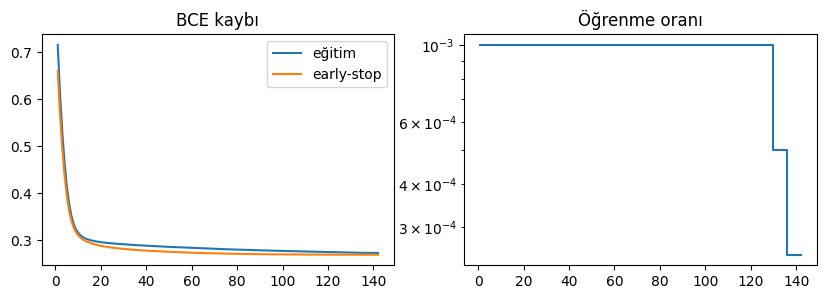

In [24]:
from sklearn.metrics import average_precision_score

y_egit, y_deg = y_dev[egit_idx], y_dev[deg_idx]
for ad, ayar in [("M1 (AdamW)", {}), ("M3 (SGD)", {"optimizer": "sgd"})]:
    s = mlp_egit(ayar, X_egit.reset_index(drop=True), y_egit)
    ap = average_precision_score(y_deg, olasilik(s, X_deg))
    print(f"{ad}: AP={ap:.3f} | en iyi epoch={s['en_iyi_epoch']} | durdu={s['durma_epoch']} | {s['sure']:.1f}s")

g = s["gecmis"]   # son eğitilen (SGD) için grafik
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(g.epoch, g.egitim_kaybi, label="eğitim"); ax[0].plot(g.epoch, g.es_kaybi, label="early-stop")
ax[0].legend(); ax[0].set_title("BCE kaybı")
ax[1].step(g.epoch, g.lr); ax[1].set_yscale("log"); ax[1].set_title("Öğrenme oranı")
plt.show()

In [25]:
import json
from sklearn.model_selection import ParameterSampler
from scipy.stats import loguniform

M1 = dict(optimizer="adamw", gizli=[32], aktivasyon="relu", lr=1e-3, weight_decay=1e-4,
          batch=64, dropout=0.0, olcek="standard", kirp=False, scheduler=True)
manuel = {
    "M1": {**M1},
    "M2": {**M1, "optimizer": "adam"},
    "M3": {**M1, "optimizer": "sgd"},
    "M4": {**M1, "olcek": "minmax"},
    "M5": {**M1, "gizli": [64, 32]},
    "M6": {**M1, "scheduler": False},
}

uzay = {"gizli": [[16], [32], [64], [64, 32], [128, 64]], "aktivasyon": ["relu", "tanh"],
        "weight_decay": [0.0, 1e-5, 1e-4, 1e-3], "batch": [32, 64, 128],
        "olcek": ["standard", "minmax", "robust"], "dropout": [0.0, 0.2], "kirp": [False, True]}
lr_araligi = {"sgd": (1e-3, 1e-1), "adam": (1e-4, 1e-2), "adamw": (1e-4, 1e-2)}

rastgele, k = {}, 1
for i, opt in enumerate(["sgd", "adam", "adamw"]):
    alan = {**uzay, "lr": loguniform(*lr_araligi[opt])}
    for p in ParameterSampler(alan, n_iter=2, random_state=SEED + 7 + i):
        rastgele[f"R{k}"] = {"optimizer": opt, **p, "lr": float(f"{p['lr']:.3g}"), "scheduler": True}
        k += 1

json.dump(manuel, open("manual_configs.json", "w"), indent=2)
json.dump(rastgele, open("random_configs.json", "w"), indent=2)
pd.DataFrame(rastgele).T

,optimizer,aktivasyon,batch,dropout,gizli,kirp,lr,olcek,weight_decay,scheduler
R1,sgd,relu,64,0.0,"[128, 64]",True,0.0228,standard,0.0001,True
R2,sgd,tanh,64,0.2,"[64, 32]",False,0.0316,robust,0.001,True
R3,adam,relu,64,0.0,[32],False,0.000409,standard,0.00001,True
R4,adam,relu,128,0.2,[16],False,0.00927,minmax,0.0,True
R5,adamw,relu,128,0.2,[32],False,0.00187,robust,0.0,True
R6,adamw,relu,128,0.0,[64],True,0.008,robust,0.0001,True


In [28]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score,
                             f1_score, balanced_accuracy_score, confusion_matrix)
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

def metrikler(y_gercek, p, esik=0.5):
    tahmin = (p >= esik).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_gercek, tahmin, labels=[0, 1]).ravel()
    return {"AP": average_precision_score(y_gercek, p), "ROC_AUC": roc_auc_score(y_gercek, p),
            "Accuracy": accuracy_score(y_gercek, tahmin),
            "Precision": precision_score(y_gercek, tahmin, zero_division=0),
            "Sensitivity": recall_score(y_gercek, tahmin), "Specificity": tn / (tn + fp),
            "F1": f1_score(y_gercek, tahmin), "Balanced_Accuracy": balanced_accuracy_score(y_gercek, tahmin)}

ic_kf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED + 5)

def ic_arama(adaylar, X, y, baglam):
    satirlar = []
    for kod, ayar in adaylar.items():
        for j, (tr, va) in enumerate(ic_kf.split(X, y), 1):
            s = mlp_egit(ayar, X.iloc[tr].reset_index(drop=True), y[tr])
            satirlar.append({"baglam": baglam, "aday": kod, "ic_kat": j,
                             "AP": average_precision_score(y[va], olasilik(s, X.iloc[va])),
                             "en_iyi_epoch": s["en_iyi_epoch"], "sure": s["sure"]})
    sonuc = pd.DataFrame(satirlar)
    ozet = sonuc.groupby("aday", sort=False).agg(AP_ort=("AP", "mean"), AP_sd=("AP", "std"),
                                                 epoch=("en_iyi_epoch", "mean"), sure=("sure", "sum"))
    return sonuc, ozet

def logreg():
    return Pipeline([("on", on_isleme_yap("standard")), ("clf", LogisticRegression(max_iter=2000))])

In [29]:
dis_kf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED + 4)
tum_ic, dis_sonuclar = [], []

for k, (tr, ev) in enumerate(dis_kf.split(X_dev, y_dev), 1):
    X_tr, y_tr = X_dev.iloc[tr].reset_index(drop=True), y_dev[tr]
    X_ev, y_ev = X_dev.iloc[ev].reset_index(drop=True), y_dev[ev]

    for yontem, adaylar in [("manuel", manuel), ("rastgele", rastgele)]:
        sonuc, ozet = ic_arama(adaylar, X_tr, y_tr, f"dis{k}")
        sonuc["yontem"] = yontem; tum_ic.append(sonuc)
        secilen = ozet["AP_ort"].idxmax()                       # iç CV'de en iyi aday
        s = mlp_egit(adaylar[secilen], X_tr, y_tr)              # outer-train'de yeniden eğit
        dis_sonuclar.append({"kat": k, "model": f"MLP-{yontem}", "secilen": secilen,
                             **metrikler(y_ev, olasilik(s, X_ev))})   # outer-eval: tek ölçüm
        print(f"Kat {k} | {yontem}: seçilen {secilen} (iç AP {ozet.loc[secilen, 'AP_ort']:.3f}) "
              f"→ dış AP {dis_sonuclar[-1]['AP']:.3f}")

    for ad, model in [("LogReg", logreg()), ("Dummy", DummyClassifier(strategy="prior"))]:
        model.fit(X_tr, y_tr)
        dis_sonuclar.append({"kat": k, "model": ad, "secilen": "-",
                             **metrikler(y_ev, model.predict_proba(X_ev)[:, 1])})

dis_df = pd.DataFrame(dis_sonuclar)
dis_df.to_csv("outer_cv_results.csv", index=False)

ozet_tablo = dis_df.groupby("model", sort=False)[["AP", "ROC_AUC", "F1", "Sensitivity", "Specificity", "Balanced_Accuracy"]] \
                   .agg(lambda s: f"{s.mean():.3f} ± {s.std():.3f}")
ozet_tablo

Kat 1 | manuel: seçilen M1 (iç AP 0.444) → dış AP 0.411
Kat 1 | rastgele: seçilen R2 (iç AP 0.447) → dış AP 0.404
Kat 2 | manuel: seçilen M5 (iç AP 0.416) → dış AP 0.379
Kat 2 | rastgele: seçilen R1 (iç AP 0.419) → dış AP 0.379
Kat 3 | manuel: seçilen M4 (iç AP 0.426) → dış AP 0.402
Kat 3 | rastgele: seçilen R5 (iç AP 0.429) → dış AP 0.405


,AP,ROC_AUC,F1,Sensitivity,Specificity,Balanced_Accuracy
model,,,,,,
MLP-manuel,0.397 ± 0.017,0.758 ± 0.030,0.194 ± 0.127,0.122 ± 0.085,0.991 ± 0.007,0.556 ± 0.039
MLP-rastgele,0.396 ± 0.015,0.755 ± 0.032,0.205 ± 0.096,0.127 ± 0.067,0.990 ± 0.008,0.559 ± 0.030
LogReg,0.422 ± 0.030,0.762 ± 0.009,0.345 ± 0.054,0.244 ± 0.056,0.980 ± 0.006,0.612 ± 0.025
Dummy,0.110 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.500 ± 0.000


In [30]:
dev_sonuc = []
for yontem, adaylar in [("manuel", manuel), ("rastgele", rastgele)]:
    sonuc, ozet = ic_arama(adaylar, X_dev, y_dev, "tam_dev")
    sonuc["yontem"] = yontem; dev_sonuc.append(sonuc)
    print(yontem); print(ozet.round(3), "\n")

hepsi = pd.concat(dev_sonuc)
ozet_tum = hepsi.groupby("aday", sort=False)["AP"].mean()
nihai = ozet_tum.idxmax()
print("NİHAİ KONFİGÜRASYON:", nihai, "| iç AP:", round(ozet_tum[nihai], 4))
pd.concat(tum_ic + dev_sonuc).to_csv("inner_cv_results.csv", index=False)
json.dump({"nihai": nihai, "ayar": {**manuel, **rastgele}[nihai]}, open("final_selection.json", "w"), indent=2)

manuel
      AP_ort  AP_sd    epoch   sure
aday                               
M1     0.428  0.065   14.333  2.796
M2     0.429  0.067   14.333  1.567
M3     0.424  0.080  125.000  5.959
M4     0.407  0.050   19.333  1.840
M5     0.414  0.063    9.000  1.700
M6     0.428  0.065   14.333  1.650 

rastgele
      AP_ort  AP_sd   epoch   sure
aday                              
R1     0.425  0.087  11.667  1.588
R2     0.415  0.068   8.333  1.642
R3     0.433  0.071  34.667  3.198
R4     0.395  0.046  19.000  1.107
R5     0.427  0.072  15.000  0.986
R6     0.415  0.070   5.333  0.650 

NİHAİ KONFİGÜRASYON: R3 | iç AP: 0.4335
